<a href="https://colab.research.google.com/github/AAMINABIBI/AI-engineering/blob/main/DL/CNN_Practice2_YT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as f
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets,transforms
from torchvision.utils import make_grid


import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
#convert MNIST image file into Tensor of 4 dimensiojn

transform = transforms.ToTensor()
#train data
train_data = datasets.MNIST(root='/cnn_data',train=True,download=True,transform=transform)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 498kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.56MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.4MB/s]


In [4]:
#test data

test_data = datasets.MNIST(root='/cnn_data',train=False,download=True,transform=transform)

In [6]:
train_data


Dataset MNIST
    Number of datapoints: 60000
    Root location: /cnn_data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [8]:
test_data

Dataset MNIST
    Number of datapoints: 10000
    Root location: /cnn_data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [9]:
#Create a small batch size

train_loader=DataLoader(train_data,batch_size=10,shuffle=True)
test_loader=DataLoader(test_data,batch_size=10,shuffle=False)

In [10]:
#define CNN Model
#Describe Convolutional layer and what it is doing---->2 convulutional layer

conv1=nn.Conv2d(1,6,3,1)
conv2=nn.Conv2d(6,16,3,1)



In [12]:
#Grab  MNIST records

for i,(x_train,y_train) in enumerate(train_data):
  break


In [13]:
x_train.shape

torch.Size([1, 28, 28])

In [14]:
x=x_train.view(1,28,28)

Convultion layer

In [15]:
#Perform first conolution


x=f.relu(conv1(x))


In [18]:
x.shape# we didn't set paddingg so we loose 2 pixel

#6=>filters,26*26=?image size

torch.Size([6, 26, 26])

Pooling layer

In [20]:
#pass through pooling layer

x=f.max_pool2d(x,2,2)#kernel 2, stride 2

In [21]:
x.shape    #26/2=13

torch.Size([6, 13, 13])

2nd convulutional layer

In [22]:
# seconf convulutuional layer


x=f.relu(conv2(x))

In [23]:
x.shape#Again we didn't set paddingg so we loose 2 pixel

torch.Size([16, 11, 11])

2nd pooling layer

In [24]:
x=f.max_pool2d(x,2,2)

In [25]:
x.shape #again 11/2

torch.Size([16, 5, 5])

Model

In [29]:
class ConvolutionalNetwork(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1=nn.Conv2d(1,6,3,1)
    self.conv2=nn.Conv2d(6,16,3,1)

    #fully connected layer of neuron
    self.fc1=nn.Linear(5*5*16,120)
    self.fc2=nn.Linear(120,84)
    self.fc3=nn.Linear(84,10)


    #forward function
  def forward(self,x):
    x=f.relu(self.conv1(x))
    x=f.max_pool2d(x,2,2)
    x=f.relu(self.conv2(x))
    x=f.max_pool2d(x,2,2)

    #flatten it out ->re view
    x=x.view(-1,5*5*16) #-1 that will very batch size

    #fully connected layers

    x=f.relu(self.fc1(x))
    x=f.relu(self.fc2(x))
    x=self.fc3(x)

    return f.log_softmax(x,dim=1)

In [31]:
#create an instance of model

torch.manual_seed(41)
model=ConvolutionalNetwork()
model

ConvolutionalNetwork(
  (conv1): Conv2d(1, 6, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [32]:
#loss function optimizer

criterion=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=0.01)
#smaller the lr,the longer it take to train

In [34]:
import time
start_time=time.time()

#create variable to track
epochs=5
train_losses=[]
test_losses=[]
train_correct=[]
test_correct=[]

#for loop of epocshs

for i in range(epochs):
  trn_corr=0
  tst_corr=0
  #train
  for b,(x_train,y_train) in enumerate(train_loader):
    b+=1 #start batch at 1
    y_pred=model(x_train) #get predicted val
    loss=criterion(y_pred,y_train) #compare prediction to correct ans win y_train

    predicted=torch.max(y_pred.data,1)[1]  # add up correct predictions at 1st index
    batch_corr=(predicted==y_train).sum() #total number of correct from this specific batch
    trn_corr+=batch_corr  #keep track


   #update parametrs

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    #print
    if b%600==0:
      print(f'epoch:{i} batch:{b} loss:{loss.item()}')

  train_losses.append(loss)
  train_correct.append(trn_corr)


  #test
  with torch.no_grad():
    for b,(x_test,y_test) in enumerate(test_loader):
      y_val=model(x_test)
      predicted=torch.max(y_val.data,1)[1]
      tst_corr+=(predicted==y_test).sum()

    loss=criterion(y_val,y_test)
    test_losses.append(loss)
    test_correct.append(tst_corr)



  #print results
#test

current_time=time.time()
print(current_time-start_time)

total_time=current_time-start_time
print(f'total time is {total_time/60} minutes!')

epoch:0 batch:600 loss:0.01122160442173481
epoch:0 batch:1200 loss:0.5097795128822327
epoch:0 batch:1800 loss:0.27345114946365356
epoch:0 batch:2400 loss:0.5706523656845093
epoch:0 batch:3000 loss:0.010505528189241886
epoch:0 batch:3600 loss:0.1338011920452118
epoch:0 batch:4200 loss:0.0005176571430638433
epoch:0 batch:4800 loss:0.10394303500652313
epoch:0 batch:5400 loss:0.2622598111629486
epoch:0 batch:6000 loss:0.0009407080942764878
epoch:1 batch:600 loss:0.010575367137789726
epoch:1 batch:1200 loss:0.004694225732237101
epoch:1 batch:1800 loss:0.06041830778121948
epoch:1 batch:2400 loss:0.08412185311317444
epoch:1 batch:3000 loss:1.2497214078903198
epoch:1 batch:3600 loss:0.5397676229476929
epoch:1 batch:4200 loss:0.005220157094299793
epoch:1 batch:4800 loss:0.0007686594035476446
epoch:1 batch:5400 loss:0.0005603323224931955
epoch:1 batch:6000 loss:0.08629796653985977
epoch:2 batch:600 loss:0.6476114988327026
epoch:2 batch:1200 loss:0.00787670724093914
epoch:2 batch:1800 loss:0.0650

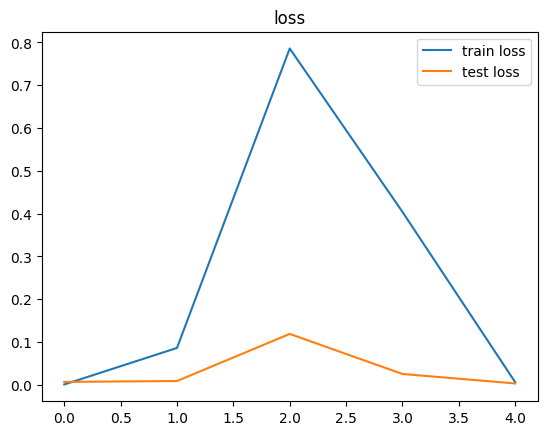

In [37]:
#graph the loss
train_losses=[t1.item() for t1 in train_losses]
test_losses=[t1.item() for t1 in test_losses]
plt.plot(train_losses,label='train loss')
plt.plot(test_losses,label='test loss')
plt.title('loss')
plt.legend()